# 07 · Comparativa final de RNN, LSTM y GRU en el test

**Objetivo:** medir en el periodo de test (enero de 2024 → noviembre de 2026) las tres redes y los modelos de referencia, y comprobar cómo se comporta el modelo final que usa la aplicación.

**Protocolo** (`scripts/train.py test`):
1. Cada red usa la configuración final de la búsqueda (notebook 06): **ventana común de 20 días** y los hiperparámetros elegidos en la validación walk-forward 2019-2023.
2. Se entrena con todos los datos anteriores a 2024, dejando un hueco (*embargo*) de *h* días para que ningún objetivo de entrenamiento se solape con el test, y con la misma regla de parada temprana.
3. Se repite con **5 semillas**. La predicción evaluada es la media de las cinco, y su dispersión mide la **estabilidad**.
4. El **modelo final** de cada horizonte (red, versión ajustada y peso) y el método del **intervalo del 80 %** se fijaron en validación **antes de calcular el test** (`modelo_final.json`, notebook 08). Aquí no se elige nada: solo se mide.
5. El tiempo de entrenamiento se mide en las mismas condiciones para todas las redes (CPU).

```bash
poetry run python scripts/train.py test --round 5
```

**Cómo leer los números:** el error principal es el RMSE en dólares por barril, que castiga más los errores grandes; el MAE es el error medio tal cual, y el MSE es el cuadrado del RMSE (en dólares al cuadrado). Los tres miden cuánto se desvía la previsión del precio real, no un beneficio. *RMSE / ingenuo* = 1 es empatar con «el precio dentro de *h* días será el de hoy»; por debajo de 1, la red lo mejora. *Mejora %* es lo mismo en porcentaje (positivo = mejor que el ingenuo).

> **Fechas del test:** el origen de cada predicción va de enero de 2024 al último día cuyo objetivo ya se conoce (datos hasta el 3 de noviembre de 2026). A 1 año, el primer objetivo cae en enero de 2025, por eso ese horizonte tiene menos predicciones.

In [1]:
import pandas as pd

from oil_forecast import test_report as report
from oil_forecast.plotting import set_style

set_style()
pd.set_option("display.float_format", "{:.3f}".format)
r = report.load()  # final round: reports/results/ronda_5

## 1. Error por barril y tabla comparativa (requisito del enunciado)

Primero, el resumen en dólares: RMSE, MAE y MSE del ingenuo frente a los del modelo final de cada plazo, con el RMSE de las tres redes al lado.

In [2]:
report.dollar_table(r).style.format(precision=2)

,Modelo final,RMSE ingenuo,RMSE final,MAE ingenuo,MAE final,MSE ingenuo,MSE final,RMSE RNN simple,RMSE LSTM,RMSE GRU
Plazo,,,,,,,,,,
1 semana,LSTM,5.82,5.81,3.85,3.85,33.87,33.78,5.77,5.81,5.78
3 meses,"RNN simple (peso 0,9)",20.06,21.96,12.83,14.26,402.44,482.06,22.27,19.50,20.47
1 año,LSTM,25.80,24.07,19.76,19.90,665.63,579.33,24.63,24.07,24.20


La tabla completa da, para cada horizonte: MAE, RMSE, mejora frente al ingenuo, número de parámetros y tiempo de entrenamiento por semilla. Se añaden el acierto de dirección (si sube o baja), la desviación de la mejora entre las 5 semillas y dos formas de medir la incertidumbre de la mejora:

- **p-valor de Diebold-Mariano:** ¿la diferencia con el ingenuo es significativa? Usa varianza de Newey-West y la corrección de Harvey, porque las predicciones de días seguidos comparten casi todo su periodo objetivo.
- **IC 95 % de la mejora:** intervalo por *bootstrap* por bloques (`metrics.bootstrap_skill`). Se remuestrean bloques de días consecutivos de al menos *h* días, para respetar ese solapamiento. A 1 año solo caben unos dos bloques en el test, así que ese intervalo es **orientativo**: puede salir descentrado y no sirve como prueba.

*Combinación* es la media de las tres redes.

In [3]:
report.comparison_table(r)

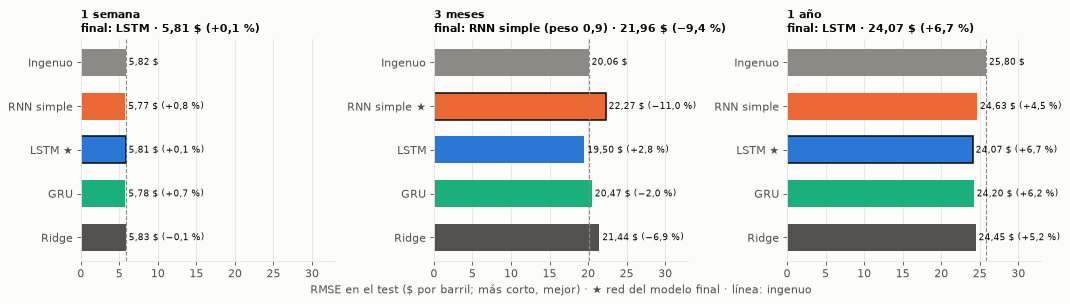

In [4]:
report.comparison_plot(r);

Todos los paneles comparten el eje en dólares, para que una mejora del 0,8 % se vea tan pequeña como es.

- **1 semana:** todo está en 0,99-1,00. La mejor red (RNN simple) baja el RMSE de 5,82 $ a 5,77 $, unos 5 céntimos por barril. Ninguna red sale significativa. Solo la combinación de las tres queda justo por debajo de 0,05 (p = 0,047; IC de +0,0 % a +1,2 %), con una mejora del 0,7 %, unos 4 céntimos. En `comparativa.csv` también salen por debajo de 0,05 algunas versiones ajustadas, con mejoras aún menores (0,2-0,5 %). Es una diferencia real pero sin valor práctico.
- **3 meses:** solo la **LSTM** mejora al ingenuo (+2,8 %: 19,50 $ frente a 20,06 $), y su intervalo incluye pérdidas (de −4,8 % a +4,8 %). La RNN simple, la mejor en validación, es la peor del test (−11,0 %). Es la única diferencia clara del test, pero en contra: el intervalo queda entero por debajo de cero (de −19,6 % a −4,8 %). La regresión Ridge también pierde (−6,9 %).
- **1 año:** las tres redes y Ridge bajan el RMSE: **LSTM +6,7 %** (24,07 $ frente a 25,80 $), GRU +6,2 %, Ridge +5,2 %, RNN simple +4,5 %. El **error medio** solo baja de verdad con la GRU (MAE −11,8 %) y Ridge (−11,4 %); con la LSTM sube un poco (19,90 $ frente a 19,76 $). Ninguna diferencia es significativa (p > 0,05): con menos de dos años de objetivos y predicciones que se solapan casi un año, el test tiene muy poca potencia.

### R²: cuánto explica cada modelo

El R² compara el error de un modelo con el de predecir la media del periodo: 1 es perfecto, 0 es igual que la media y negativo es peor. Esa media no se conoce de antemano, así que el R² solo dice algo **al lado del del ingenuo**. Se da de dos formas:

- **Sobre el precio:** mide sobre todo que el precio de dentro de *h* días se parece al de hoy.
- **Sobre el cambio de precio** (el retorno logarítmico a *h* días, que es lo que predicen las redes): el ingenuo predice siempre cambio cero, así que no explica nada. Su R² sale algo por debajo de 0 porque la media del test no es exactamente cero. Un valor positivo es información que añade la red.

In [5]:
report.r2_table(r).style.format(precision=3)

,Modelo final,R² precio ingenuo,R² precio final,R² cambio ingenuo,R² cambio final,R² cambio RNN simple,R² cambio LSTM,R² cambio GRU
Plazo,,,,,,,,
1 semana,LSTM,0.873,0.873,-0.002,0.002,0.009,0.002,0.010
3 meses,"RNN simple (peso 0,9)",-0.396,-0.672,-0.015,-0.243,-0.287,0.052,-0.028
1 año,LSTM,-0.706,-0.485,-0.031,0.121,0.070,0.121,0.107


- **1 semana:** 0,873 sobre el precio, exactamente lo mismo que el ingenuo. Parece un modelo excelente, pero solo refleja que el precio de dentro de una semana se parece al de hoy. Sobre el cambio de precio sale 0,002: la red no explica nada del movimiento.
- **3 meses:** sobre el precio sale negativo incluso para el ingenuo (−0,40). En 2024-2025 el precio se movió en un rango estrecho y luego llegó el shock de 2026, así que los errores a 3 meses son grandes frente a la variación total del periodo. El modelo final queda por debajo del ingenuo en las dos medidas (−0,67 y −0,24). Solo la LSTM tiene un R² positivo sobre el cambio de precio (0,052).
- **1 año:** es el único plazo con señal. La LSTM explica el 12 % de la variación del cambio de precio (0,121) y la GRU el 10,7 %, frente a −0,03 del ingenuo. Sobre el precio, la LSTM saca −0,49 y el ingenuo −0,71.

El R² cuenta lo mismo que el RMSE y el MAE: empate a 1 semana, peor a 3 meses y algo de señal a 1 año.

## 2. El modelo final en el test

El modelo de la aplicación se eligió en validación: en cada horizonte, la red con menor error medio en 2019-2023, multiplicada por el peso que eligió la regla (peso 1 = la red tal cual). La tabla lo pone al lado de su resultado en el test, junto con la cobertura del intervalo del 80 %.

In [6]:
report.final_table(r).style.format({"Peso": "{:g}", "Validación 2019-2023": "{:.3f}", "Test 2024-2026": "{:.3f}",
                                      "Mejora RMSE %": "{:+.1f}", "Mejora MAE %": "{:+.1f}", "p-valor DM": "{:.2f}",
                                      "Cobertura test %": "{:.1f}", "Anchura media ($)": "{:.1f}"})

,Modelo,Peso,Validación 2019-2023,Test 2024-2026,Mejora RMSE %,IC 95 % mejora,Mejora MAE %,p-valor DM,Intervalo 80 %,Cobertura test %,Anchura media ($)
Horizonte,,,,,,,,,,,
1 semana,LSTM,1,1.000,0.999,+0.1,[-0.4; +0.6],+0.1,0.59,Conformal escalado por volatilidad,78.9,13.0
3 meses,RNN simple,0.9,0.972,1.094,-9.4,[-16.0; -3.0],-11.1,0.06,Histórico (precio de hoy),79.8,35.4
1 año,LSTM,1,0.903,0.933,+6.7,[-29.9; +14.1],-0.7,0.74,Histórico (precio de hoy),87.0,80.1


- **1 semana (LSTM):** 1,000 en validación y 0,999 en el test. Se comporta igual que en validación: empata con el ingenuo.
- **3 meses (RNN simple, peso 0,9):** pasa de 0,972 en validación a **1,094 en el test** (−9,4 %; IC de −16 % a −3 %): no se sostiene. Es la cifra del modelo final, que multiplica la predicción de la RNN por 0,9; la RNN sin ajustar pierde un 11,0 % (apartado 1). El ajuste la acerca al ingenuo, pero no basta. La validación hacia atrás (2010-2018, notebook 08) ya la había marcado como *dudosa*.
- **1 año (LSTM):** pasa de 0,903 a **0,933**: el RMSE baja un 6,7 % y lo bajan las 5 semillas. Es el único horizonte en el que el modelo final mejora al ingenuo en validación y en el test. Pero el error medio no mejora (MAE 19,90 $ frente a 19,76 $, −0,7 %): la LSTM evita algunos errores muy grandes, sobre todo en 2026, y el resto del tiempo se equivoca igual o algo más que el ingenuo. El apartado 5 muestra que esa ventaja depende del shock de 2026.

El modelo final no se cambia después de ver el test: elegir ahora la LSTM a 3 meses porque gana en el test sería usar el test para elegir, y su +2,8 % dejaría de ser una estimación honesta. La aplicación sí enseña las tres redes de cada horizonte.

## 3. Estabilidad entre semillas

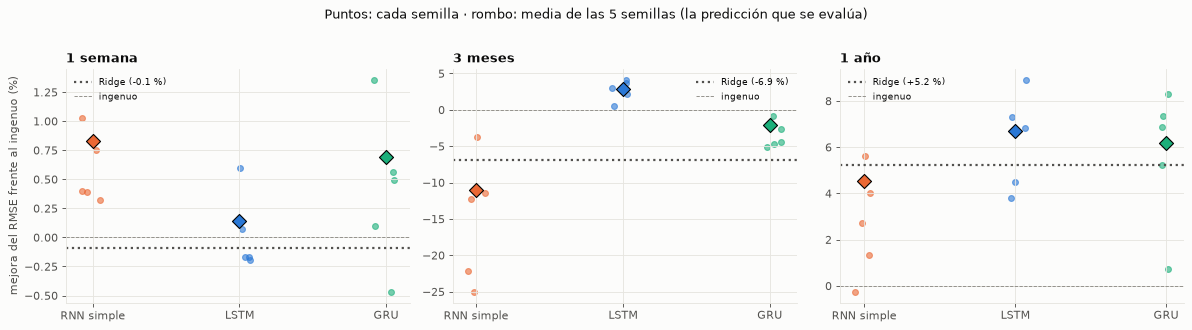

In [7]:
report.seeds_plot(r);

- **1 año:** las 5 semillas de la LSTM ganan al ingenuo (entre +3,8 % y +8,9 %), y lo mismo pasa con la GRU. La mejora no depende de una semilla afortunada.
- **3 meses:** la RNN simple va de −3,7 % a −25 %. Las curvas de aprendizaje (notebook 08) lo explican: a este horizonte la RNN alcanza su mejor punto en muy pocas épocas y después empeora deprisa, así que el resultado depende mucho de dónde corte la parada temprana. La LSTM, en cambio, gana con las 5 semillas (entre +0,5 % y +4,2 %).
- **1 semana:** todas las semillas están a menos de ±1,5 % del ingenuo.

## 4. Predicciones frente a la realidad

Predicción del modelo final, precio real, ingenuo e intervalo del 80 %. El eje horizontal es la **fecha que se predice**.

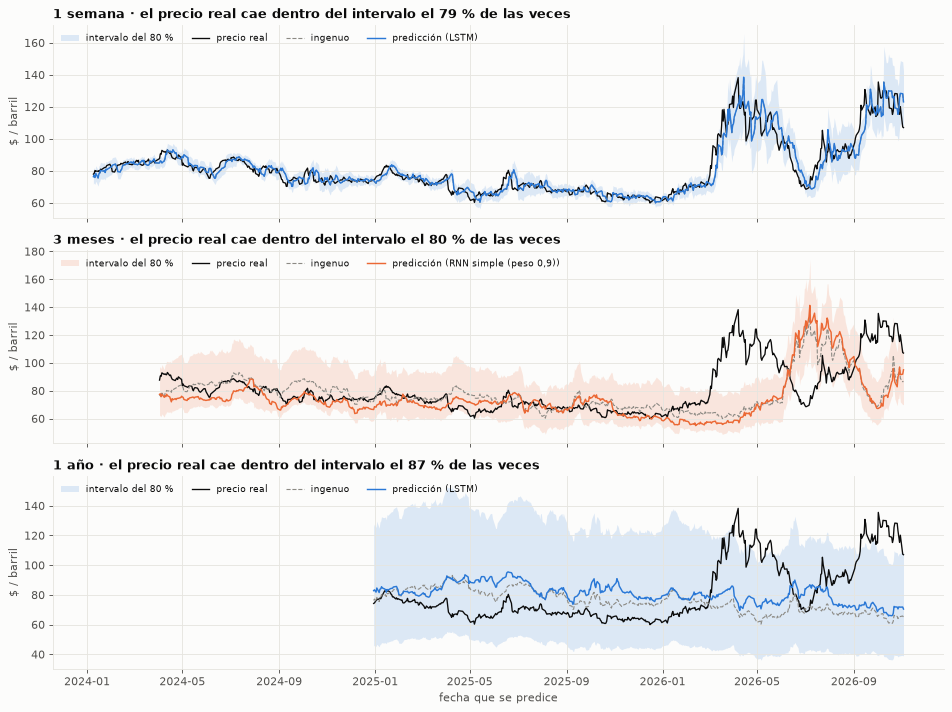

In [8]:
report.predictions_plot(r);

## 5. ¿Dónde gana y dónde pierde cada red?

**Ventaja acumulada** frente al ingenuo (diferencia acumulada de errores al cuadrado): si la curva **sube**, la red va acumulando ventaja; si **baja**, el ingenuo acierta más en ese periodo.

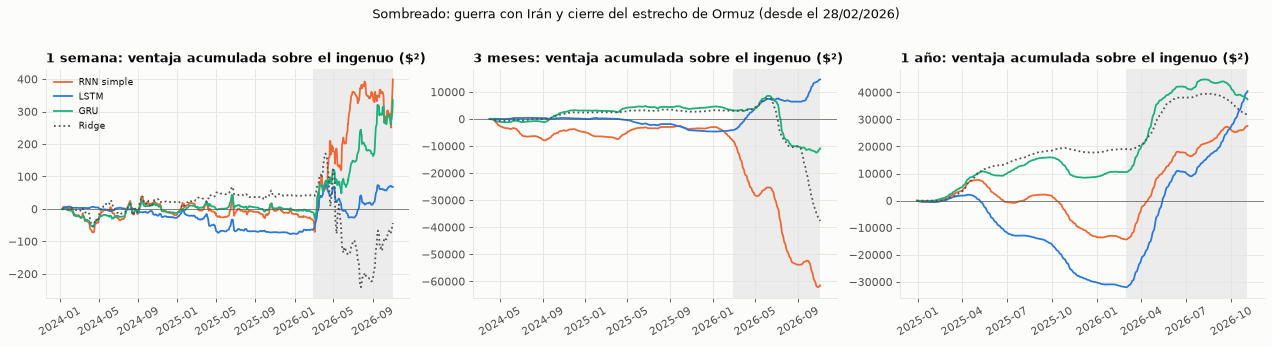

In [9]:
report.advantage_plot(r);

In [10]:
report.yearly_table(r)

El test incluye uno de los mayores shocks de la serie: con la guerra con Irán y el cierre del estrecho de Ormuz (desde el 28 de febrero de 2026), el Brent pasó de 61 $ a 127 $ en un trimestre, bajó a 70 $ y volvió a 130 $. Ese año decide buena parte del resultado:

- **3 meses:** en 2024-2025 la GRU (0,80 y 0,93) y Ridge (0,85 y 0,96) mejoraban claramente al ingenuo, pero en 2026 pierden todas salvo la LSTM. La RNN simple solo gana en 2025.
- **1 año:** la LSTM **pierde en 2025** (1,32: anticipaba precios más altos de los que hubo, cuando el Brent bajó a 60 $) y **gana en 2026** (0,86), cuando la subida por la guerra llevó el precio a la zona que predecía. La mejora total depende, por tanto, del shock de 2026 y no de haberlo anticipado. La GRU es más regular: gana en los dos años (0,88 y 0,95).
- **1 semana:** ninguna red se separa del ingenuo en ningún año (entre 0,99 y 1,01). La pequeña ventaja de la RNN simple y la GRU se acumula casi entera en 2026, con los saltos diarios del shock.

## 6. El intervalo del 80 % en el test

Porcentaje de veces que el precio real cayó dentro del intervalo del modelo final, por año de la fecha predicha. Lo ideal es estar cerca del 80 % en todos los años.

In [11]:
report.coverage_table(r)

,2024,2025,2026,Total
1 semana,80 % (n=249),80 % (n=253),77 % (n=213),78.9 % (n=715)
3 meses,100 % (n=191),98 % (n=253),40 % (n=213),79.8 % (n=657)
1 año,100 % (n=2),100 % (n=253),71 % (n=213),87.0 % (n=468)


- **1 semana (conformal escalado por volatilidad):** 79 % en total y entre el 77 % y el 80 % cada año, incluido 2026. El intervalo se ensancha cuando el mercado se agita y vuelve a estrecharse después, como se buscaba.
- **3 meses (histórico):** 80 % en total, pero por compensación: casi siempre dentro en 2024-2025 (100 % y 98 %) y solo el 40 % en 2026. Un intervalo basado en los movimientos pasados no anticipa un shock de este tamaño.
- **1 año (histórico):** 87 % en total y 71 % en 2026, pero con una anchura media de unos 80 $, que dice poco. En la aplicación se presenta como orientativo.

## 7. Coste computacional

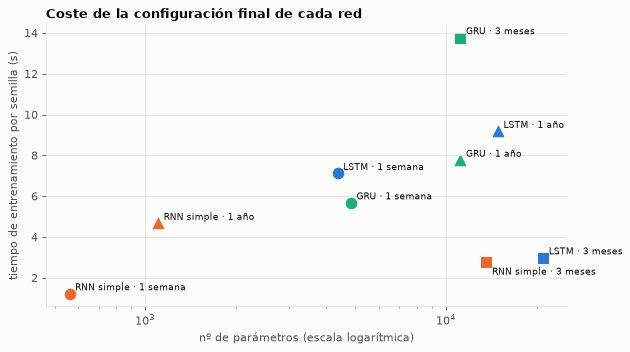

In [12]:
report.cost_plot(r);

Todas las redes son pequeñas (de 561 a 21.057 parámetros) y entrenan en segundos en CPU. La RNN simple es la más rápida de entrenar en los tres horizontes. Con el mismo tamaño de capa, la LSTM tiene unas cuatro veces más parámetros que la RNN (cuatro bloques de pesos por sus puertas, frente a uno) y la GRU unas tres veces. El coste no es un criterio que separe a las redes aquí: lo que decide es el error y su estabilidad.

## 8. Conclusiones

| Horizonte | Mejor red en el test | Modelo final (elegido en validación) | Test (RMSE / ingenuo) | Intervalo 80 % en el test |
|---|---|---|---|---|
| 1 semana | RNN simple (0,992) | LSTM | 0,999 | 79 %, estable por año |
| 3 meses | LSTM (0,972) | RNN simple, peso 0,9 | 1,094 | 80 %, solo 40 % en 2026 |
| 1 año | LSTM (0,933) | LSTM | 0,933 (MAE sin mejora) | 87 %, muy ancho |

1. **A 1 semana ninguna red aporta nada sobre el ingenuo**, como en validación y en la literatura (el precio de mañana es casi el de hoy). Lo útil a este plazo es el intervalo, que sí funciona.
2. **A 3 meses la elección hecha en validación no se sostiene.** La RNN simple era la mejor en 2019-2023, pero es inestable entre semillas y pierde un 9,4 % en el test con su ajuste (un 11,0 % sin él). La LSTM, más estable, mejora al ingenuo un 2,8 %.
3. **A 1 año la LSTM baja el RMSE un 6,7 %**, con las 5 semillas a favor, pero no el error medio (MAE −0,7 %), y la ventaja se acumula en 2026, con el shock de Ormuz. La GRU es más regular: baja el RMSE un 6,2 % y el MAE un 11,8 %, y gana en 2025 y en 2026.
4. **Entre las tres arquitecturas**, la LSTM es la más consistente: es la única que mejora al ingenuo a 3 meses y a 1 año, en validación y en el test. La RNN simple es la más barata, pero la más inestable a 3 meses. La GRU queda en medio.
5. **Una regresión lineal (Ridge) queda cerca de las redes** a 1 año (+5,2 %). Con unos 6.000 días de datos y un problema tan ruidoso, la ventaja de las redes recurrentes es pequeña.
6. **Ninguna red mejora al ingenuo de forma significativa.** Solo la combinación a 1 semana queda justo por debajo de 0,05, con 4 céntimos de mejora. Lo único claro del test es negativo: la RNN simple a 3 meses es peor que el ingenuo.
7. **El R² sobre el precio engaña:** a 1 semana sale 0,87, igual que el ingenuo. Sobre el cambio de precio da la lectura correcta: 0 a 1 semana, negativo a 3 meses y 0,12 a 1 año con la LSTM.

La aplicación usa el modelo final reentrenado con todos los datos disponibles (`scripts/entrenar_app.py`) y muestra estas cifras del test junto a cada previsión, con un indicador de fiabilidad por horizonte.